# Olist E-Commerce — Khám phá dữ liệu

Notebook này đọc trực tiếp từ `data/processed/olist.db` (do pipeline sinh ra) và
trình bày 5 phát hiện chính. Toàn bộ số liệu lấy từ các bảng `mart_*`, không tính lại bằng pandas.

**Chạy trước:** `python run_all.py`

> Báo cáo đầy đủ: `docs/findings.md`

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'run_all.py').is_file() and (p / 'src').is_dir()),
    None,
)
assert ROOT is not None, 'Open this notebook inside the olist-analytics repository'
DB = ROOT / 'data' / 'processed' / 'olist.db'
assert DB.exists(), f'Chưa có database: {DB} — chạy python run_all.py trước'
conn = sqlite3.connect(DB)
q = lambda sql: pd.read_sql_query(sql, conn)
print(f'Database: {DB}  ({DB.stat().st_size / 1e6:.0f} MB)')

Database: E:\projects\olist-analytics\data\processed\olist.db  (292 MB)


## 0. Quy mô dữ liệu

9 bảng gốc được nạp nguyên trạng vào `stg_*`, sau đó dựng thành 5 dimension + 3 fact.
Cột `rows` cho thấy độ lớn từng bảng.

In [2]:
tables = q("""
    SELECT name FROM sqlite_master
    WHERE type = 'table'
      AND (name LIKE 'stg_%' OR name LIKE 'dim_%' OR name LIKE 'fact_%')
    ORDER BY name
""")
tables['rows'] = [q(f'SELECT COUNT(*) n FROM {t}')['n'][0] for t in tables['name']]
tables

,name,rows
0,dim_customer,96096
1,dim_date,821
2,dim_geolocation,19010
3,dim_product,32951
4,dim_seller,3095
5,fact_order_items,112650
6,fact_orders,99441
7,fact_payments,103886
8,stg_category_translation,71
9,stg_customers,99441


## 1. Giao trễ phá huỷ điểm đánh giá

Đây là phát hiện mạnh nhất. Điểm review giảm **đơn điệu** theo mức độ trễ:
4,29 → 3,29 → 2,10 → 1,70 sao.

,delivery_bucket,orders,avg_review_score,pct_low_review,avg_lead_time_days
0,on_time_or_early,89672,4.291,9.25,10.98
1,late_1_3d,1869,3.291,32.14,23.29
2,late_4_7d,1802,2.103,67.68,28.23
3,late_8d_plus,2861,1.697,79.24,44.49


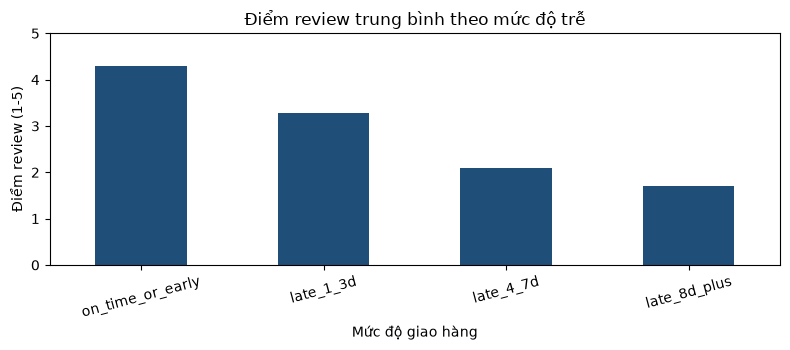

In [3]:
d = q("""
    SELECT delivery_bucket, orders, avg_review_score, pct_low_review, avg_lead_time_days
    FROM mart_delivery_impact
    WHERE delivery_bucket != 'not_delivered'
    ORDER BY sort_order
""")
display(d)

ax = d.plot.bar(x='delivery_bucket', y='avg_review_score', legend=False,
                color='#1f4e79', figsize=(8, 3.6), ylim=(0, 5),
                title='Điểm review trung bình theo mức độ trễ')
ax.set_xlabel('Mức độ giao hàng')
ax.set_ylabel('Điểm review (1-5)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [4]:
q('SELECT * FROM mart_delivery_gap').T

,0
orders_on_time,89672.000
orders_late,6532.000
late_rate_pct,6.790
avg_review_on_time,4.291
avg_review_late,2.271
review_gap,2.020
pct_low_review_on_time,9.250
pct_low_review_late,62.410
avg_lead_time_on_time,10.980
avg_lead_time_late,33.940


## 2. Khách gần như không quay lại

**Lưu ý:** phải dùng `customer_unique_id`, không phải `customer_id`.
`customer_id` là duy nhất theo từng đơn nên dùng nó sẽ cho tỷ lệ quay lại = 0%.

In [5]:
q('SELECT * FROM mart_customer_segments ORDER BY revenue DESC')

,segment,customers,pct_customers,orders,revenue,pct_revenue,avg_revenue_per_customer,avg_recency_days,avg_review_score
0,one_time,91832,96.96,91832,14797435.43,94.35,161.14,239.5,4.113
1,repeat_2,2640,2.79,5280,768090.03,4.90,290.94,224.6,4.145
2,loyal_3plus,235,0.25,798,118181.28,0.75,502.90,203.0,4.337


## 3. Seller: nhóm rủi ro nhỏ nhưng gây nhiều trễ

Mỗi điểm trên biểu đồ là một seller có ≥ 20 đơn. Kích thước điểm = số đơn.

,health_flag,sellers,orders,revenue,pct_revenue,avg_review_score,avg_late_rate_pct
0,healthy,447,44900,5679202.25,43.76,4.310,3.53
1,watch,302,37355,4655616.12,35.88,3.976,8.58
2,low_volume,971,9638,1844609.51,14.21,4.120,6.64
3,at_risk,67,5258,797738.42,6.15,3.466,18.06


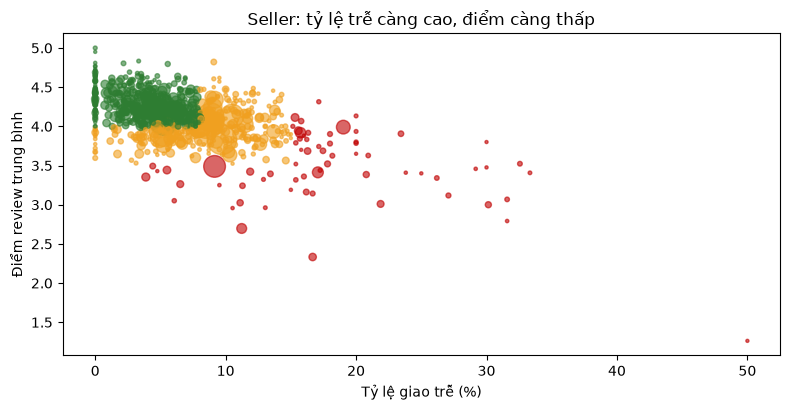

In [6]:
display(q('SELECT * FROM mart_seller_flags ORDER BY revenue DESC'))

s = q("""
    SELECT late_rate_pct, avg_review_score, orders, health_flag
    FROM mart_seller_scorecard WHERE orders >= 20
""")
colors = s['health_flag'].map({'healthy': '#2e7d32', 'watch': '#f0a020', 'at_risk': '#c00000'})
ax = s.plot.scatter(x='late_rate_pct', y='avg_review_score', s=s['orders'] / 4,
                    c=colors, alpha=0.6, figsize=(8, 4.2),
                    title='Seller: tỷ lệ trễ càng cao, điểm càng thấp')
ax.set_xlabel('Tỷ lệ giao trễ (%)')
ax.set_ylabel('Điểm review trung bình')
plt.tight_layout()
plt.show()

## 4. Địa lý: RJ trễ gấp 2,7 lần SP dù chỉ cách ~430 km

Đây là vấn đề vận hành theo tuyến, không phải khoảng cách.

In [7]:
q("""
    SELECT state, orders, ROUND(revenue, 0) AS revenue, avg_lead_time_days,
           late_rate_pct, avg_review_score
    FROM mart_state_performance
    ORDER BY revenue DESC LIMIT 12
""")

,state,orders,revenue,avg_lead_time_days,late_rate_pct,avg_review_score
0,SP,41022,5864390.0,8.74,4.50,4.212
1,RJ,12648,2104496.0,15.30,12.15,3.905
2,MG,11455,1837427.0,11.99,4.59,4.166
3,RS,5398,873885.0,15.29,6.10,4.156
4,PR,4963,791952.0,11.97,4.06,4.213
5,BA,3340,605864.0,19.33,12.17,3.885
6,SC,3591,604947.0,14.94,8.22,4.100
7,DF,2114,349379.0,12.94,5.64,4.089
8,GO,1993,340361.0,15.61,6.50,4.070
9,ES,2013,321881.0,15.78,10.75,4.054


## 5. Càng xa càng đắt, càng chậm, càng bị điểm thấp

,distance_band,orders,avg_freight,avg_lead_time_days,late_rate_pct,avg_review_score
0,1_0_100_km,18057,13.35,6.48,4.48,4.243
1,2_100_300_km,13572,18.86,9.95,5.18,4.207
2,3_300_600_km,31983,22.44,12.61,6.77,4.094
3,4_600_1000_km,18152,24.88,14.70,7.10,4.087
4,5_1000_1500_km,6691,29.80,17.25,8.86,4.015
5,7_1500_km_tro_len,8964,39.79,20.52,11.67,3.948


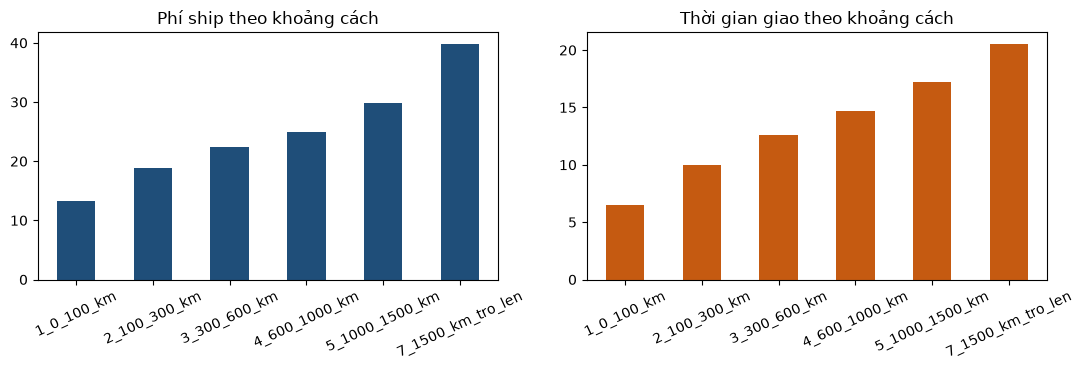

In [8]:
df = q("""
    SELECT distance_band, orders, avg_freight, avg_lead_time_days,
           late_rate_pct, avg_review_score
    FROM mart_freight_by_distance
    WHERE distance_band NOT LIKE '6_%'
    ORDER BY sort_order
""")
display(df)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
df.plot.bar(x='distance_band', y='avg_freight', legend=False, color='#1f4e79', ax=axes[0],
            title='Phí ship theo khoảng cách')
df.plot.bar(x='distance_band', y='avg_lead_time_days', legend=False, color='#c55a11', ax=axes[1],
            title='Thời gian giao theo khoảng cách')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

## Kết luận

| Phát hiện | Con số |
|---|---|
| Giao trễ mất | **2,02 sao** (4,29 → 2,27) |
| Khách trễ cho 1-2 sao | **62,41%** (so với 9,25% khi đúng hạn) |
| Khách quay lại | **3,04%** |
| Seller rủi ro | **67 seller**, 6,15% doanh thu, 18,06% trễ |
| Bang tệ nhất | **MA** (17,56% trễ), **RJ** (12,15%, 12.648 đơn) |

Đọc thêm: `docs/findings.md` (báo cáo đầy đủ) và `reports/figures/` (17 chart).

**Hạn chế:** dataset không có giá vốn, chi phí marketing hay traffic — nên không thể
kết luận về biên lợi nhuận, CAC/LTV hay tỷ lệ chuyển đổi.